In [ ]:

# ایمپورت کتابخانه

from google.colab import files
import scipy.io
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd
uploaded = files.upload()
mat_data = scipy.io.loadmat("data.mat")

knapsack_capacity = int(mat_data['W'][0][0])
weights = mat_data['w'][0]
values = mat_data['v'][0]
num_items = len(weights)

print("Knapsack Capacity:", knapsack_capacity)
print("Number of Items:", num_items)

Saving data.mat to data (2).mat
Knapsack Capacity: 1200
Number of Items: 30


In [ ]:
# پارامترهای اولیه الگوریتم ژنتیک
POP_SIZE = 100
NUM_GENERATIONS = 200
CROSSOVER_PROB = 0.8
MUTATION_PROB = 1 / num_items

# محاسبه برازندگی یک فرد
def calculate_fitness(ind):
    total_weight = np.sum(ind * weights)
    total_value = np.sum(ind * values)
    return total_value if total_weight <= knapsack_capacity else 0

# تولید یک فرد جدید به‌صورت تصادفی
def create_individual():
    return np.random.randint(0, 2, num_items)

# اعمال جهش روی یک فرد
def mutate(ind):
    for i in range(num_items):
        if random.random() < MUTATION_PROB:
            ind[i] = 1 - ind[i]  # برعکس کردن بیت
    return ind

# ترکیب دو والد برای تولید دو فرزند
def crossover(p1, p2):
    if random.random() < CROSSOVER_PROB:
        point = random.randint(1, num_items - 1)
        return (
            np.concatenate((p1[:point], p2[point:])),
            np.concatenate((p2[:point], p1[point:]))
        )
    else:
        return p1.copy(), p2.copy()

# انتخاب تناسبی
def selection(population, fitness_scores):
    total_fitness = np.sum(fitness_scores)
    if total_fitness == 0:
        return population[np.random.choice(len(population), size=POP_SIZE, replace=True)]
    probs = fitness_scores / total_fitness
    indices = np.random.choice(len(population), size=POP_SIZE, p=probs, replace=True)
    return population[indices]


In [ ]:
def genetic_algorithm():
    # جمعیت اولیه
    population = np.array([create_individual() for _ in range(POP_SIZE)])
    best_solution = None
    best_fitness = -1
    fitness_history = []

    for generation in range(NUM_GENERATIONS):
        # محاسبه برازندگی جمعیت
        fitness_scores = np.array([calculate_fitness(ind) for ind in population])

        # پیدا کردن بهترین فرد در نسل جاری
        current_best_idx = np.argmax(fitness_scores)
        current_best_fitness = fitness_scores[current_best_idx]
        current_best_solution = population[current_best_idx]

        # به‌روزرسانی بهترین راه‌حل کلی
        if current_best_fitness > best_fitness:
            best_fitness = current_best_fitness
            best_solution = current_best_solution

        fitness_history.append(best_fitness)

        # انتخاب افراد برای نسل بعد
        selected = selection(population, fitness_scores)
        next_population = []

        # تولید نسل جدید با ترکیب و جهش
        for i in range(0, POP_SIZE, 2):
            p1 = selected[i]
            p2 = selected[i + 1 if i + 1 < POP_SIZE else 0]
            c1, c2 = crossover(p1, p2)
            next_population.extend([mutate(c1), mutate(c2)])

        # بروزرسانی جمعیت
        population = np.array(next_population[:POP_SIZE])
        population[0] = best_solution.copy()  # الیتیسم: حفظ بهترین راه‌حل

        print(f"Generation {generation + 1}: Best Value = {best_fitness}")

    # ------------------------------
    # نمایش آیتم‌های انتخاب‌شده نهایی
    # ------------------------------
    selected_indices = np.where(best_solution == 1)[0]
    selected_weights = weights[selected_indices]
    selected_values = values[selected_indices]

    df = pd.DataFrame({
        "Item Index": selected_indices,
        "Weight": selected_weights,
        "Value": selected_values
    })
    df.index.name = "Selected Item"
    display(df)

    # مجموع وزن و ارزش آیتم‌های انتخاب‌شده
    total_weight = df["Weight"].sum()
    total_value = df["Value"].sum()

    print("\n================ FINAL RESULTS ================\n")
    print(f"Total Weight: {total_weight}")
    print(f"Total Value: {total_value}")
    print(f"Knapsack Capacity: {knapsack_capacity}")
    print("===============================================\n")

    # ------------------------------
    # نمودار دایره‌ای: توزیع وزن‌ها
    # ------------------------------
    plt.figure(figsize=(5, 5))
    plt.pie(df["Weight"], labels=df["Item Index"], autopct="%1.1f%%", startangle=90)
    plt.title("Weight Distribution of Selected Items")
    plt.axis("equal")
    plt.show()

    # ------------------------------
    # نمودار دایره‌ای: توزیع ارزش‌ها
    # ------------------------------
    plt.figure(figsize=(5, 5))
    plt.pie(df["Value"], labels=df["Item Index"], autopct="%1.1f%%", startangle=90)
    plt.title("Value Distribution of Selected Items")
    plt.axis("equal")
    plt.show()

    # ------------------------------
    # نمودار میله‌ای: وزن آیتم‌ها
    # ------------------------------
    plt.figure(figsize=(6, 4))
    plt.bar(df["Item Index"].astype(str), df["Weight"])
    plt.title("Weights of Selected Items")
    plt.xlabel("Item Index")
    plt.ylabel("Weight")
    plt.grid(True)
    plt.show()

    # ------------------------------
    # نمودار میله‌ای: ارزش آیتم‌ها
    # ------------------------------
    plt.figure(figsize=(6, 4))
    plt.bar(df["Item Index"].astype(str), df["Value"])
    plt.title("Values of Selected Items")
    plt.xlabel("Item Index")
    plt.ylabel("Value")
    plt.grid(True)
    plt.show()


Generation 1: Best Value = 639
Generation 2: Best Value = 667
Generation 3: Best Value = 667
Generation 4: Best Value = 694
Generation 5: Best Value = 746
Generation 6: Best Value = 746
Generation 7: Best Value = 746
Generation 8: Best Value = 752
Generation 9: Best Value = 752
Generation 10: Best Value = 752
Generation 11: Best Value = 794
Generation 12: Best Value = 794
Generation 13: Best Value = 845
Generation 14: Best Value = 845
Generation 15: Best Value = 845
Generation 16: Best Value = 845
Generation 17: Best Value = 845
Generation 18: Best Value = 845
Generation 19: Best Value = 845
Generation 20: Best Value = 845
Generation 21: Best Value = 845
Generation 22: Best Value = 845
Generation 23: Best Value = 845
Generation 24: Best Value = 871
Generation 25: Best Value = 871
Generation 26: Best Value = 871
Generation 27: Best Value = 871
Generation 28: Best Value = 871
Generation 29: Best Value = 871
Generation 30: Best Value = 871
Generation 31: Best Value = 871
Generation 32: Be

,Item Index,Weight,Value
Selected Item,,,
0,0,60,74
1,1,69,28
2,3,88,78
3,6,80,53
4,8,129,82
5,12,129,58
6,13,67,73
7,17,59,93
8,19,61,94



================ FINAL RESULTS ================

Total Weight: 1195
Total Value: 920
Knapsack Capacity: 1200



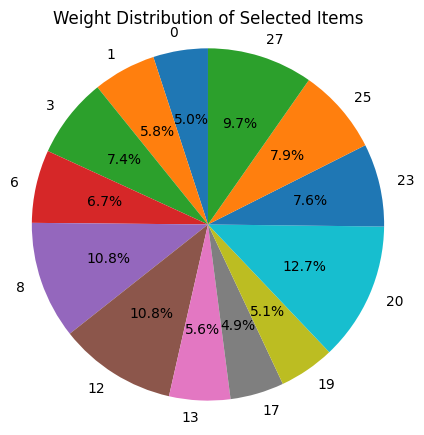

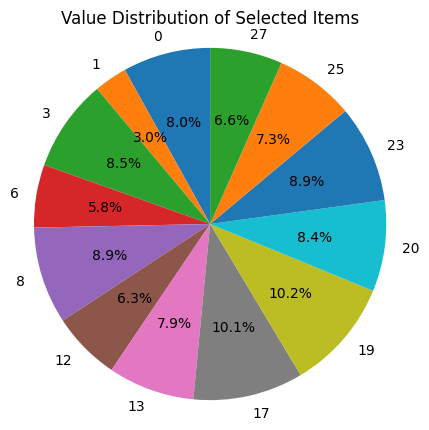

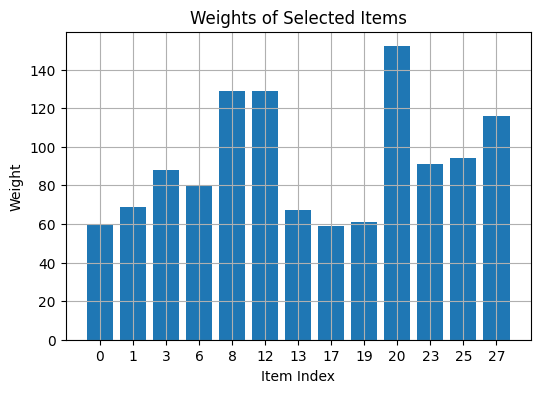

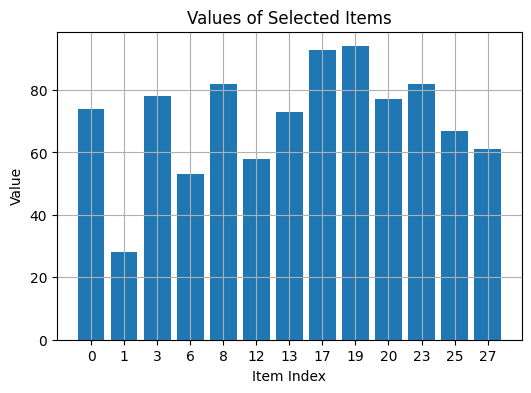

In [ ]:

#  ران الگوریتم

genetic_algorithm()
